# Predicting Self-Reported Diabetes Status Using Health and Lifestyle Indicators: A CRISP-DM Analysis of the 2015 CDC BRFSS Dataset

### **Module:** DBMS71008 Data Analytics | CRISP-DM CA2 | **Student:** Ahmad Shahzad - T00269209 | **Github:**

# Phase 1: Business Understanding

## 1.1 Context and Problem

Diabetes is a long term health condition that affects how the body controls blood sugar levels. It is a major health concern because it can lead to serious complications, including heart disease, kidney problems and nerve damage

Several factors such as age, body mass index (BMI), physical activity, smoking and existing health conditions, may be associated with diabetes. However, understanding how these factors relate to diabetes can be challenging because individuals have different lifestyles and health characteristics.

The project aims to investigate the relationship between health and lifestyle indicators and reported diabetes status

**Research Question:** To what extent can does demographic characteristics, lifestyle behaviors and health indicators predict whether an individual reports having diabetes?

## 1.2 Stakeholders & Users

| Stakeholder / User | Role | Interest in the project / How they are affected |
|---|---|---|
|Public Health Researchers| Primary User | Can use the analysis to investigate relationships between health indicators, lifestyle behaviours and reported diabetes status|
|Healthcare Professionals | Secondary User | Could use the findings to support health awareness campaigns and population-level strategies|
|Survey Respondents and the General Public| Affected | Could indirectly benefit from improved public health research, but may also be affected by inaccurate predictions or biased conclusions|

## 1.3 Business / Practical Objective

**Practical Objective:** To help public health researchers better understand the demographic, lifestyle and health factors associated with diabetes

## 1.4 Analytical Objective


**Analytical OBjective:** Build a binary classifier that distinguishes individuals who report having diabetes from those who do not, using demographic characteristics, lifestyle behaviours and health indicators. Evaluate whether the model outperforms a majority-class baseline using recall and F1-score for the diabetes-positive class.

Recall is particularly important because failing to identify individuals who report having diabetes (false negatives) is a concern when investigating patterns that could support public health research.

## 1.5 Success Criteria

### Technical

|Criterion|Reason|
|---|---|
|Achieve higher recall and F1-score than the majority-class baseline| Demonstrates that the model can identify respondents reporting diabetes rather than simply predicting the most common class|
|Compare at least two classification models| Helps determine which model performs better at distinguishing respondents with and without reported diabetes|
|Evaluate precision, recall and F1-score and the confusion matrix| Provides a better understanding of model performance, particularly, false negatives and false positives

### Practical

|Criterion|Reason|
|---|---|
|Present findings using clear graphs, tables and explanations | Makes the results easier for people without a machine learning background to understand|
|Identify the health and lifestyle indicators most strongly associated with reported diabetes| Helps public health researchers understand which factors are most relevant to reported diabetes status|

## 1.6 Constraints and Assumptions

|Constraint| Reason|
|---|---|
|Project Deadline| Project is due on 4 December 2026|
|Self-reported health information| Diabetes status and other indicators are based on survey responses rather than independently verified clinical measurements|

<br>

|Assumption| Reasons|
|---|---|
|Historical Data| The analysis assumes the historical data is suitable for exploring relationships, while recognising that population health patterns may have changed since 2015|
|Binary physical activity| The PhysActivity column records whether a respondent participated in physical activity outside work during the past 30 days but does not measure its duration, frequency or intensity. For example, someone who walks for 20 minutes and someone who runs for an hour may both receive a value of 1. This lack of detail could potentially affect the model's predictions and the interpretation of physical activity as a predictor of reported diabetes.|

<br>

## 1.7 Project Plan

**Tools:** Jupyter Notebook, Python, GitHub


| CRISP-DM Phase | Planned Activities | Deadlines |
|---|---|---|
|1.Business Understanding | Define research question, context & problem, stakeholders, success criteria, constraints and assumptions| 09 Nov - 10 Nov|
|2. Data Understanding | Data Collection, Data Description, Data dictionary, Exploration, Quality | 10 Nov - 12 Nov|
|3. Data Preparation | Select columns, clean data, handle missing data, preparation log | 12 Nov - 13 Nov|
|4. Modelling | Majority Baseline, Logistic regression, Random Forrest | 13 Nov - 19 Nov|
|5. Evaluation | Precision, recall, F1-score, confusion matrices, success criteria, limitations | 19 Nov - 22 Nov |
|6. Deployment| Recommendations, Reflection, Responsible Ai Collaboration, Research Paper |22 Nov - 4 Dec |







# Environment Setup

In [ ]:

python -m pip install pandas numpy matplotlib seaborn scikit-learn jupyter ipykernel jinja2


   -------------------- ------------------- 1/2 [jinja2]
   ---------------------------------------- 2/2 [jinja2]

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Import libraries used


import pandas as pd  
import numpy as np  
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix


# Phase 2: Data Understanding

## 2.1 Data Collection Report

|Item Type | Detail|
|---|---|
|Data Source | [Diabetes Health Indicators Dataset](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset)|
|Publisher|  The original survey data was collected and published by the Centers for Disease Control and Prevention (CDC). This project uses a processed version published on Kaggle by Alex Teboul, who selected and recoded variables from the original CDC BRFSS 2015 dataset.|
|Access Date | 10/11/2026|
|License| CC0 1.0 Universal|
|Unit of Analysis| Individual survey respondent|
|Known Limits| The dataset is based on self-reported survey responses rather than clinically verified diagnoses. It contains data from 2015, so the findings may not fully represent current populations. |
|Files | `diabetes_binary_health_indicators_BRFSS2015.csv` – the CSV file selected for this project from the Kaggle dataset.|





## 2.2 Data Description Report

### 2.2.1 Dataset dimensions and unit of analysis

In [4]:
# Load the dataset

df = pd.read_csv("../Data/Raw/diabetes_binary_health_indicators_BRFSS2015.csv")

#Number of rows and columns
print("Number of rows: ", df.shape[0])
print("Number of columns: ", df.shape[1])

display(df.head())


Number of rows:  253680
Number of columns:  22


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


**Interpretation:** The dataset contains 253,680 number of observations and 22 columns

Each row represents one respondent's demographic characteristics, lifestyle behaviours, health indicators and reported diabetes status

### 2.2.2 Variables names, data types and valid ranges

In [6]:
## Display column names

print("Variable Names:")
print(df.columns.tolist)

df.info()

Variable Names:
<bound method IndexOpsMixin.tolist of Index(['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker',
       'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education',
       'Income'],
      dtype='str')>
<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null 

In [8]:
# Summary of data types and observed ranges

variable_summary = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Minimum": df.min(),
    "Maximum": df.max(),
    "Unique Values": df.nunique()
})

display(variable_summary)

,Data Type,Minimum,Maximum,Unique Values
Diabetes_binary,float64,0.0,1.0,2
HighBP,float64,0.0,1.0,2
HighChol,float64,0.0,1.0,2
CholCheck,float64,0.0,1.0,2
BMI,float64,12.0,98.0,84
Smoker,float64,0.0,1.0,2
Stroke,float64,0.0,1.0,2
HeartDiseaseorAttack,float64,0.0,1.0,2
PhysActivity,float64,0.0,1.0,2
Fruits,float64,0.0,1.0,2


**Interpreation:**

The dataset contains 22 variable names, all stored as float64. However these variables represent different types of information.

Most variables are binary indicators with value of 0 and 1, representing characteristics such asd smoking status, high blood pressure, and physical activity.

BMI is a numerical measurement with observed values ranging from 12 to 98. MentHlth and PhysHlth represent the number of days respondents reported poor mental or physical health during the previous 30 days, ranging from 0 to 30.

Other variables use ordered categories, including Age(1-13), GenHlth(1-5), Education(1-6), and Income(1-8).

The findings show that all variables are stored numerically, they have different meanings and measurement types

### 2.2.3 Data Dictionary and Variables Roles

In [15]:

# Assigning default role to every column
roles = dict.fromkeys(df.columns, "Candidate Predictor")

# Identifying the target variable
roles.update({
    "Diabetes_binary": "Target"
})

data_dictionary = pd.DataFrame({
    "Data Type: ": df.dtypes.astype(str),
    "Unique": df.nunique(),
    "Example": df.iloc[0],
    "Role": pd.Series(roles)
})

descriptions = {
    "Diabetes_binary": "Self-reported diabetes status",
    "HighBP": "High blood pressure",
    "HighChol": "High cholesterol",
    "CholCheck": "Cholesterol checked within the past 5 years",
    "BMI": "Body mass index",
    "Smoker": "Smoked at least 100 cigarettes in lifetime",
    "Stroke": "History of stroke",
    "HeartDiseaseorAttack": "History of heart disease or heart attack",
    "PhysActivity": "Physical activity outside work in the past 30 days",
    "Fruits": "Consumes fruit at least once per day",
    "Veggies": "Consumes vegetables at least once per day",
    "HvyAlcoholConsump": "Heavy alcohol consumption",
    "AnyHealthcare": "Has healthcare coverage",
    "NoDocbcCost": "Unable to see a doctor due to cost in past 12 months",
    "GenHlth": "Self-rated general health",
    "MentHlth": "Days of poor mental health in the past 30 days",
    "PhysHlth": "Days of poor physical health in the past 30 days",
    "DiffWalk": "Serious difficulty walking or climbing stairs",
    "Sex": "Respondent sex",
    "Age": "Respondent age group",
    "Education": "Highest education category",
    "Income": "Household income category"
}

data_dictionary["Meaning"] = pd.Series(descriptions)

display(data_dictionary)

,Data Type:,Unique,Example,Role,Meaning
Diabetes_binary,float64,2,0.0,Target,Self-reported diabetes status
HighBP,float64,2,1.0,Candidate Predictor,High blood pressure
HighChol,float64,2,1.0,Candidate Predictor,High cholesterol
CholCheck,float64,2,1.0,Candidate Predictor,Cholesterol checked within the past 5 years
BMI,float64,84,40.0,Candidate Predictor,Body mass index
Smoker,float64,2,1.0,Candidate Predictor,Smoked at least 100 cigarettes in lifetime
Stroke,float64,2,0.0,Candidate Predictor,History of stroke
HeartDiseaseorAttack,float64,2,0.0,Candidate Predictor,History of heart disease or heart attack
PhysActivity,float64,2,0.0,Candidate Predictor,Physical activity outside work in the past 30 ...
Fruits,float64,2,0.0,Candidate Predictor,Consumes fruit at least once per day


**Interpreation** 

The data dictionary contains 22 variables from the dataset. The column names, data types, unique values and examples.

**target variable** - Diabetes_binary is identified as the target variable, wth the remaining 21 variables considered candidate predictors. No dedicated respondent identifier was included in the dataset

the data dictionary provides a reference for understanding the variables and will help guide data quality checks and preparation decisions in later phases



## 2.3 Data Exploration Report

### 2.3.1 Target Variable Distribution



Negative: 218334
Positive: 35346


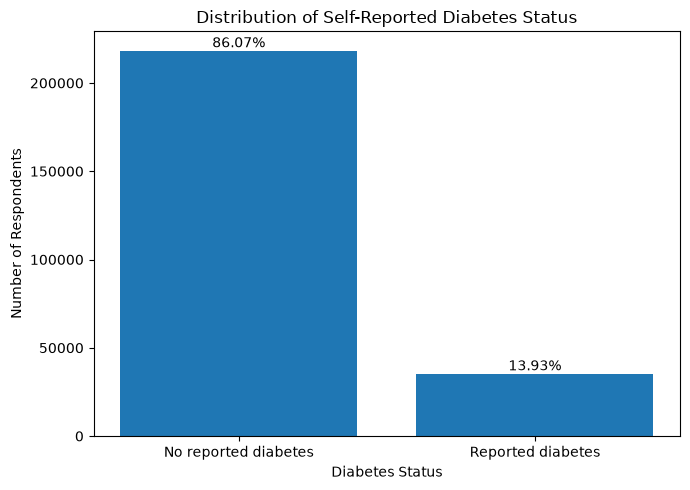

In [26]:
# Calculating the frequency of each diabetes class
target_counts = df["Diabetes_binary"].value_counts().sort_index()

print("Negative:", target_counts[0])
print("Positive:", target_counts[1])

#Calculating the percentage of each diabetes class
target_percentage = (
    df["Diabetes_binary"].value_counts(normalize=True).sort_index() * 100
)

#Summary table of results
target_summary = pd.DataFrame({
    "Frequency": target_counts,
    "Percentage (%)": target_percentage
})


target_summary.index = ["No reported diabetes", "Reported diabetes"]

plt.figure(figsize=(7,5))

bars = plt.bar(
    target_summary.index,
    target_summary["Frequency"]
)

for bar, percentage in zip(bars, target_summary["Percentage (%)"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percentage:.2f}%",
        ha="center",
        va="bottom"
    )

plt.title("Distribution of Self-Reported Diabetes Status")
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Respondents")

plt.tight_layout()
plt.show()

**Interpretation**

The target variable shows that most respondents did not report having diabetes. Approximately 86.07% of respondents belong to the negative class, while 13.93% belong to the diabetes positive class.

This indicates that the dataset has an imbalanced target distribution, with substantially fewer respondents reporting diabetes. The imbalance will be important for the modelling stage as a model could achieve high accuracy by predicting the majority class. Therefore, additional evaluation measures such as recall, precision and F1-score will be considered when assessing model performance

### 2.3.2 Demographic Characteristics

This section explores the relationship between demographic characteristics and self-reported diabetes. The age, sex and income are examined to identify differences in the proportion of respondents reporting across demographic groups

**Age:**

,Respondents,Reported Diabetes,Diabetes (%)
Age,,,
1.0,5700,78,1.37
2.0,7598,140,1.84
3.0,11123,314,2.82
4.0,13823,626,4.53
5.0,16157,1051,6.50
6.0,19819,1742,8.79
7.0,26314,3088,11.74
8.0,30832,4263,13.83
9.0,33244,5733,17.25


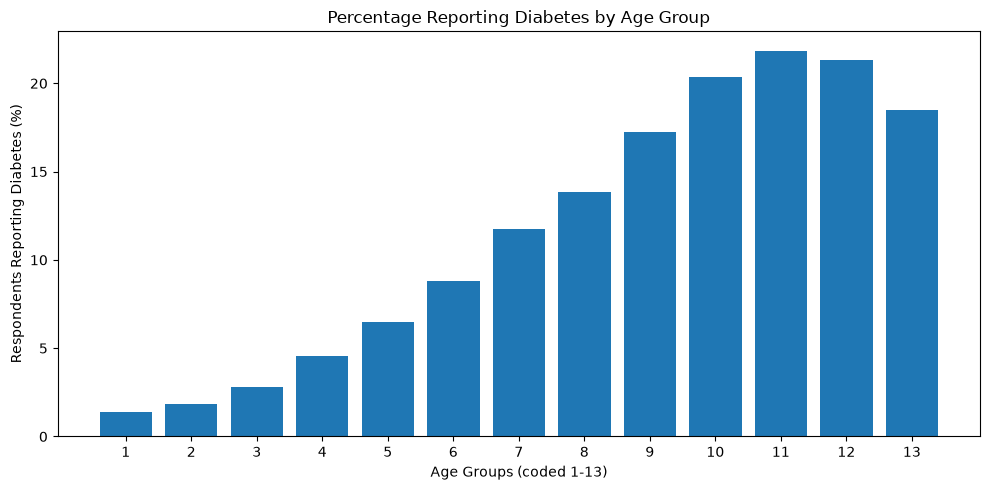

In [38]:
age_counts = df.groupby("Age")["Diabetes_binary"].size()

age_positive = df.groupby("Age")["Diabetes_binary"].sum()

age_percentage = (
    df.groupby("Age")["Diabetes_binary"].mean() * 100
)

age_summary = pd.DataFrame({
    "Respondents": age_counts,
    "Reported Diabetes": age_positive.astype(int),
    "Diabetes (%)": age_percentage.round(2)
})

display(age_summary)


# Bar chart
plt.figure(figsize=(10,5))

plt.bar(
    age_summary.index.astype(int).astype(str),
    age_summary["Diabetes (%)"]
)

plt.title("Percentage Reporting Diabetes by Age Group")
plt.xlabel("Age Groups (coded 1-13)")
plt.ylabel("Respondents Reporting Diabetes (%)")

plt.tight_layout()
plt.show()

**Interpreation**

Respondents in age groups 7-13 account for the majority of reported diabetes cases, while respondents in age group 1-6 report fewer cases.
The percentage of respondents reporting diabetes generally increase across the age groups, from 1.37% in age group 1 to a peak of 21.85% in age group 11. However, the percentage decreases slightly in age group 12 and 13.

This suggests that older age groups are associated with a higher proportion of reported diabetes compared with younger age groups. Although diabetes is also reported in younger age groups, the proportions are considerably lower.

These findings are a result suggest that age may be a useful predictor of reported diabetes status, but they do establish a casual relationship


<br>

**Gender / Sex**

,Respondents,Reported_Diabetes,Diabetes_Percentage
Female,"141,974","18,411",12.97%
Male,"111,706","16,935",15.16%


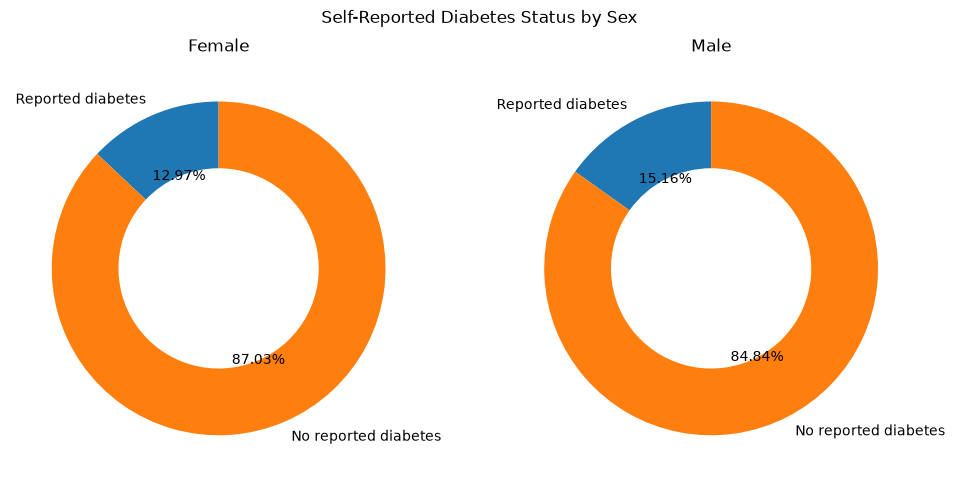

In [ ]:
gender_summary = df.groupby("Sex")["Diabetes_binary"].agg(
    Respondents="count",
    Reported_Diabetes="sum",
    Diabetes_Percentage="mean"
)

gender_summary["Diabetes_Percentage"] *= 100

gender_summary.index = ["Female","Male"]

display(gender_summary.style.format({
    "Respondents": "{:,.0f}",
    "Reported_Diabetes": "{:,.0f}",
    "Diabetes_Percentage": "{:.2f}%"
}))



# Two donut charts to compare diabetes percentages by Sex
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, (sex, row) in zip(axes, gender_summary.iterrows()):
    positive = row["Diabetes_Percentage"]
    negative = 100 - positive

    ax.pie(
        [positive, negative],
        labels=["Reported diabetes", "No reported diabetes"],
        autopct="%.2f%%",
        startangle=90,
        wedgeprops={"width": 0.4}
    )

    ax.set_title(sex)

plt.suptitle("Self-Reported Diabetes Status by Sex")
plt.tight_layout()
plt.show()


**Interpretation**

The dataset contains 141,974 female respondents and 111,706 male respondents. The two charts show that 12.97% of female respondents reported diabetes, compared with 15.16% of male respondents.

Although there are more female respondents in the dataset, the percentage of reporting diabetes is slightly higher among males, with a difference of 2.19 percentage points between the two groups.

This suggests that there is some variation in reported diabetes status between males and females, although the difference is relatively small compared with the difference observed across age groups.

Based on this initial exploration, gender may have a weaker relationship with reported diabetes status than age. However, further analysis and modeling will be needed to determine how useful it is as a predictor.

<br>

**Income**

,Respondents,Reported_Diabetes,Diabetes_Percentage
Income,,,
1.000000,"9,811","2,383",24.29%
2.000000,"11,783","3,086",26.19%
3.000000,"15,994","3,568",22.31%
4.000000,"20,135","4,054",20.13%
5.000000,"25,883","4,504",17.40%
6.000000,"36,470","5,291",14.51%
7.000000,"43,219","5,265",12.18%
8.000000,"90,385","7,195",7.96%


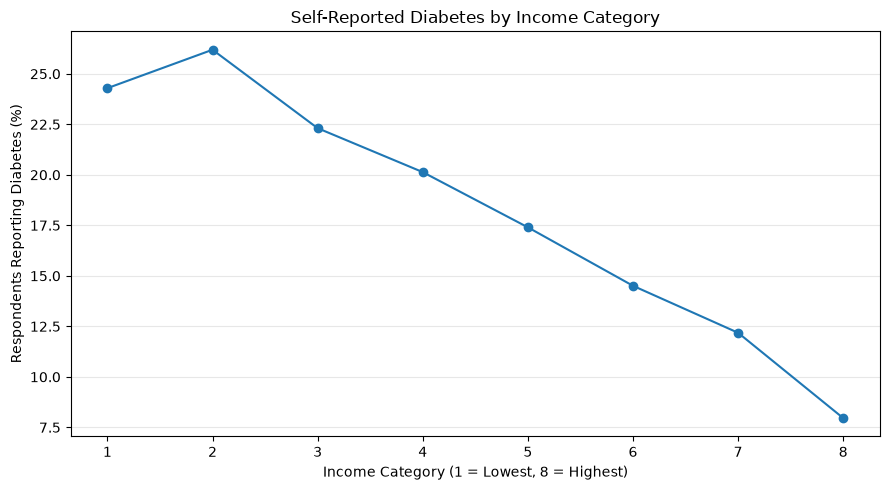

In [47]:

# Group respondents by income category
income_summary = df.groupby("Income")["Diabetes_binary"].agg(
    Respondents="count",
    Reported_Diabetes="sum",
    Diabetes_Percentage="mean"
)

# Convert proportions into percentages
income_summary["Diabetes_Percentage"] *= 100

# Display the results with commas and percentages
display(income_summary.style.format({
    "Respondents": "{:,.0f}",
    "Reported_Diabetes": "{:,.0f}",
    "Diabetes_Percentage": "{:.2f}%"
}))


plt.figure(figsize=(9, 5))

plt.plot(
    income_summary.index,
    income_summary["Diabetes_Percentage"],
    marker="o"
)

plt.title("Self-Reported Diabetes by Income Category")
plt.xlabel("Income Category (1 = Lowest, 8 = Highest)")
plt.ylabel("Respondents Reporting Diabetes (%)")

plt.xticks(range(1, 9))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



**Interpretation**

The income analysis shows that the percentage of diabetes reports generally decrease as income increases. Income category 2 has the highest percentage of reported diabetes at 26.19%, while income category 8 has the lowest at 7.96%.

Although income category 8 has the highest number of respondents reporting diabetes, it also has the highest number of respondents overall. Therefore comparing percentages provides a clearer understanding of the difference between income groups.

The results suggest that respondents in lower income categories are more likely to report diabetes than those in higher categories. However, this is an observed association and not does mean that income directly causes diabetes.

These findings suggest that income may be a useful predictor of reported diabetes, although its predictive value will need to be assessed during modelling.

### 2.3.3 Lifestyle Behaviours

This section explores whether lifestyle behaviours are associated with reported diabetes status

<br>

**Smoking**

,Respondents,Reported_Diabetes,Diabetes_Percentage
Non-smoker,"141,257","17,029",12.06%
Smoker,"112,423","18,317",16.29%


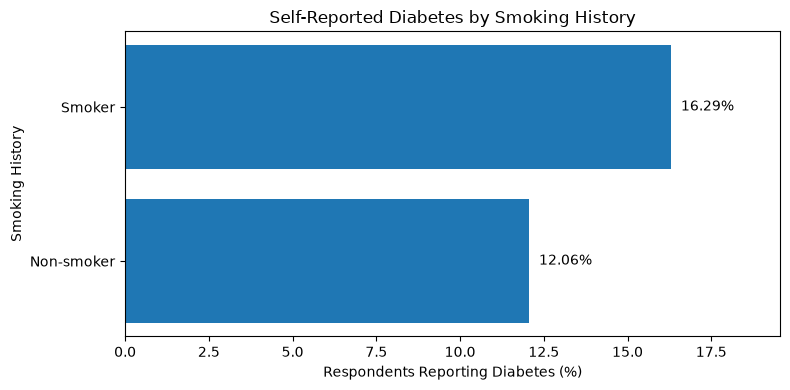

In [52]:
#Grouping respondents by smoking

smoking_summary = df.groupby("Smoker")["Diabetes_binary"].agg(
    Respondents="count",
    Reported_Diabetes="sum",
    Diabetes_Percentage="mean"
)

#Percentages
smoking_summary["Diabetes_Percentage"] *=100

smoking_summary.index = ["Non-smoker","Smoker"]

display(smoking_summary.style.format({
    "Respondents": "{:,.0f}",
    "Reported_Diabetes": "{:,.0f}",
    "Diabetes_Percentage": "{:.2f}%"
}))


plt.figure(figsize=(8, 4))

bars = plt.barh(
    smoking_summary.index,
    smoking_summary["Diabetes_Percentage"]
)

# Display percentages beside each bar
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )

plt.title("Self-Reported Diabetes by Smoking History")
plt.xlabel("Respondents Reporting Diabetes (%)")
plt.ylabel("Smoking History")

plt.xlim(0, smoking_summary["Diabetes_Percentage"].max() * 1.2)

plt.tight_layout()
plt.show()



<br>

**Physical Health**

,Respondents,Reported_Diabetes,Diabetes_Percentage
No physical activity,"61,760","13,059",21.14%
Physical activity,"191,920","22,287",11.61%


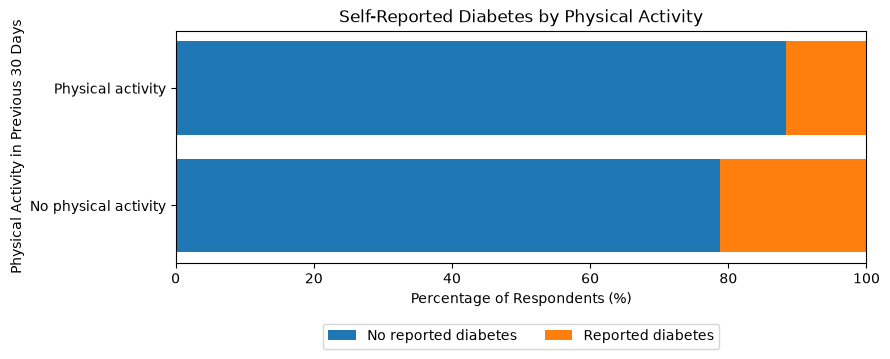

In [53]:

# Group respondents by physical activity
activity_summary = df.groupby("PhysActivity")["Diabetes_binary"].agg(
    Respondents="count",
    Reported_Diabetes="sum",
    Diabetes_Percentage="mean"
)

# Convert proportions into percentages
activity_summary["Diabetes_Percentage"] *= 100

# Replace numeric codes with readable labels
activity_summary.index = ["No physical activity", "Physical activity"]

# Display the summary table
display(activity_summary.style.format({
    "Respondents": "{:,.0f}",
    "Reported_Diabetes": "{:,.0f}",
    "Diabetes_Percentage": "{:.2f}%"
}))


# Calculate percentages for both outcomes
reported = activity_summary["Diabetes_Percentage"]
not_reported = 100 - reported

plt.figure(figsize=(9, 4))

plt.barh(
    activity_summary.index,
    not_reported,
    label="No reported diabetes"
)

plt.barh(
    activity_summary.index,
    reported,
    left=not_reported,
    label="Reported diabetes"
)

plt.title("Self-Reported Diabetes by Physical Activity")
plt.xlabel("Percentage of Respondents (%)")
plt.ylabel("Physical Activity in Previous 30 Days")
plt.xlim(0, 100)

plt.legend(loc="lower center", bbox_to_anchor=(0.5, -0.4), ncol=2)
plt.tight_layout()
plt.show()



**Interpretation**

>Smoking: 

Out of 141,257 respondents who reported not having smoked at least 100 cigarettes in their lifetime, 12.06% reported diabetes, corresponding to 17,029 respondents. In comparison, out of 112,423 respondents with a smoking history, 16.29% reported diabetes, corresponding to 18,317 respondents.

Although the dataset contains more respondents without a smoking history, those with a smoking history have a higher percentage of reported diabetes. There is a difference of 4.23 percentage points between the two groups.

<br>

>*Physical Activity over 30 days:

The graph shows that respondents who reported no physical activity during the previous 30 days had a higher percentage of self-reported diabetes at 21.14%, compared with 11.61% among respondents who reported physical activity.

Although the physically active group was considerably larger, with 191,920 respondents compared with 61,760 respondents in the inactive group, the percentage reporting diabetes was much lower.

There is a difference of 9.53 percentage points between the two groups. The percentage reporting diabetes among physically active respondents was approximately 45.08% lower relative to respondents who reported no physical activity.

### 2.3.4 Health Indicators

**Body Mass Index (BMI)**